<a href="https://colab.research.google.com/github/Rupesh756/Brain-tumor-Detection-using-deep-learning/blob/main/brain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
train_dir = "/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Training"
test_dir  = "/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing"

In [43]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [44]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

Found 4492 images belonging to 4 classes.
Found 1599 images belonging to 4 classes.


In [45]:
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224,224,3))

# Freeze base model
for layer in base_model.layers:
    layer.trainable = False

# Custom layers
x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)
output = layers.Dense(4, activation='softmax')(x)

model = models.Model(inputs=base_model.input, outputs=output)

In [46]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [47]:
EPOCHS = 20

history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=EPOCHS
)

Epoch 1/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.7765 - loss: 0.5864 - val_accuracy: 0.7492 - val_loss: 0.6961
Epoch 2/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 245s 2s/step - accuracy: 0.8393 - loss: 0.4097 - val_accuracy: 0.8093 - val_loss: 0.5740
Epoch 3/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8624 - loss: 0.3565 - val_accuracy: 0.8380 - val_loss: 0.5372
Epoch 4/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 268s 2s/step - accuracy: 0.8698 - loss: 0.3336 - val_accuracy: 0.8274 - val_loss: 0.5711
Epoch 5/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8849 - loss: 0.3108 - val_accuracy: 0.8505 - val_loss: 0.4979
Epoch 6/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.8760 - loss: 0.3003 - val_accuracy: 0.8305 - val_loss: 0.5785
Epoch 7/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.8902 - loss: 0.2981 - val_accuracy: 0.8368 - val_loss: 0.5388
Epoch 8/20
141/141 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.8923 - loss: 0.2785 - val_accu

### Image Validation Script

This script will go through your training and testing directories, attempt to open each file, and report any that cause an `UnidentifiedImageError`.

In [37]:
from PIL import Image
import os

def validate_images_in_directory(directory_path):
    invalid_images = []
    print(f"\nValidating images in: {directory_path}")
    for root, _, files in os.walk(directory_path):
        for file in files:
            file_path = os.path.join(root, file)
            try:
                # Attempt to open the image
                with Image.open(file_path) as img:
                    img.verify() # Verify that it is an image
                # print(f"Successfully validated: {file_path}") # Uncomment for verbose output
            except (IOError, SyntaxError) as e:
                # Catch PIL errors (e.g., UnidentifiedImageError)
                invalid_images.append((file_path, str(e)))
                print(f"[ERROR] Invalid image detected: {file_path} - {e}")
            except Exception as e:
                # Catch any other unexpected errors
                invalid_images.append((file_path, str(e)))
                print(f"[ERROR] Unexpected error with file: {file_path} - {e}")

    if not invalid_images:
        print("No invalid images found in this directory.")
    else:
        print(f"Found {len(invalid_images)} invalid images in {directory_path}:")
        for img_path, error_msg in invalid_images:
            print(f"- {img_path}: {error_msg}")
    return invalid_images

# Validate training data directory
print("Starting validation for training directory...")
invalid_train_images = validate_images_in_directory(train_dir)

# Validate testing data directory
print("\nStarting validation for testing directory...")
invalid_test_images = validate_images_in_directory(test_dir)

print("\nImage validation complete.")

if invalid_train_images or invalid_test_images:
    print("\nPlease remove or replace the listed invalid files from your dataset directories.")
else:
    print("All images validated successfully. You can now retry training your model.")


Starting validation for training directory...

Validating images in: /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Training
No invalid images found in this directory.

Starting validation for testing directory...

Validating images in: /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing
[ERROR] Invalid image detected: /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg - cannot identify image file '/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg'
Found 1 invalid images in /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing:
- /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg: cannot identify image file '/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg'

Image validation complete.

Please remove or replace the listed invalid files from your dataset directories.


It appears the file `/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg` is corrupted or not a valid image. You can remove it using the following code.

In [39]:
import os

file_to_remove = '/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg'

if os.path.exists(file_to_remove):
    os.remove(file_to_remove)
    print(f"Removed: {file_to_remove}")
else:
    print(f"File not found: {file_to_remove}")


File not found: /content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/notumor/Te-no_167.jpg


After removing the invalid file, please re-run the cell `jOc35Wu53zqV` to re-initialize your `ImageDataGenerator` objects (`train_data` and `test_data`) with the corrected dataset. Then you can retry training your model with cell `1TnlKiJw4ct6`.

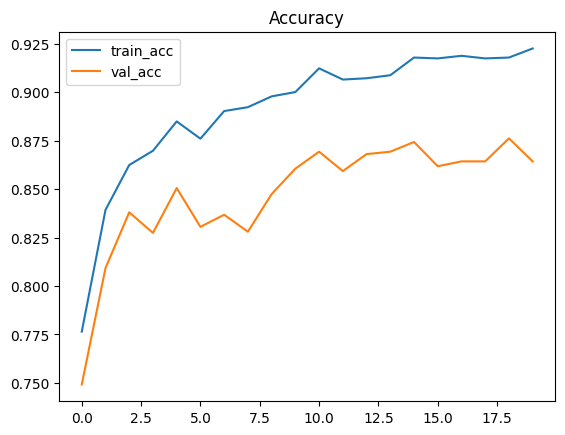

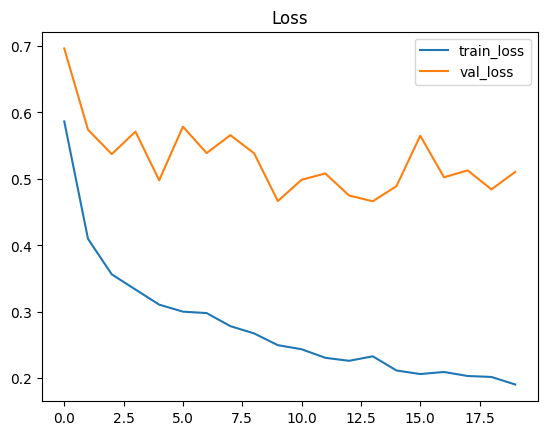

In [48]:
plt.plot(history.history['accuracy'], label='train_acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.title("Loss")
plt.show()

In [49]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)

50/50 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.8643 - loss: 0.5104
Test Accuracy: 0.864290177822113


In [51]:
model.save("/content/drive/MyDrive/brain_tumor_model.keras")

In [54]:
import numpy as np
from tensorflow.keras.preprocessing import image

img_path = "/content/drive/MyDrive/Colab Notebooks/brain/unzipdataset/Testing/glioma/Te-gl_1.jpg"  # change path
img = image.load_img(img_path, target_size=(224,224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)
class_names = list(train_data.class_indices.keys())

print("Predicted:", class_names[np.argmax(prediction)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted: meningioma
